# Chapter 6 — Two-view geometry

Companion notebook to **Chapter 6**. Epipolar lines, the essential matrix and its four decompositions, the
eight-point and five-point algorithms, triangulation, and the two degeneracies that matter most for a mower: a flat
lawn and turning on the spot.

Conventions: matched points are in **normalised** coordinates ($K^{-1}$ applied); the relative pose $(R,\mathbf t)$
maps camera-1 coordinates to camera-2 coordinates, $\mathbf q_2 = R\mathbf q_1+\mathbf t$, and $E=\mathbf t^\wedge R$.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent            # the code/ directory
sys.path[:0] = [str(ROOT), str(ROOT / "examples")]

import cv2
import numpy as np
import matplotlib.pyplot as plt
from vslam import lie, twoview as tv
from ch06_twoview import mower_scene, estimate_all, rot_err_deg, dir_err_deg, F_PX

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(0)
# after the imports: the example scripts select the Agg backend
%matplotlib inline

## 1. Epipolar lines (Proposition 6.1)

A garden scene with 0.3 m of relief, seen by the mower before and after moving 30 cm. For a few points of image 1,
the epipolar line $E\tilde{\mathbf x}_1$ in image 2 passes through the corresponding point; all lines meet at the
epipole, the image of the first camera's centre.

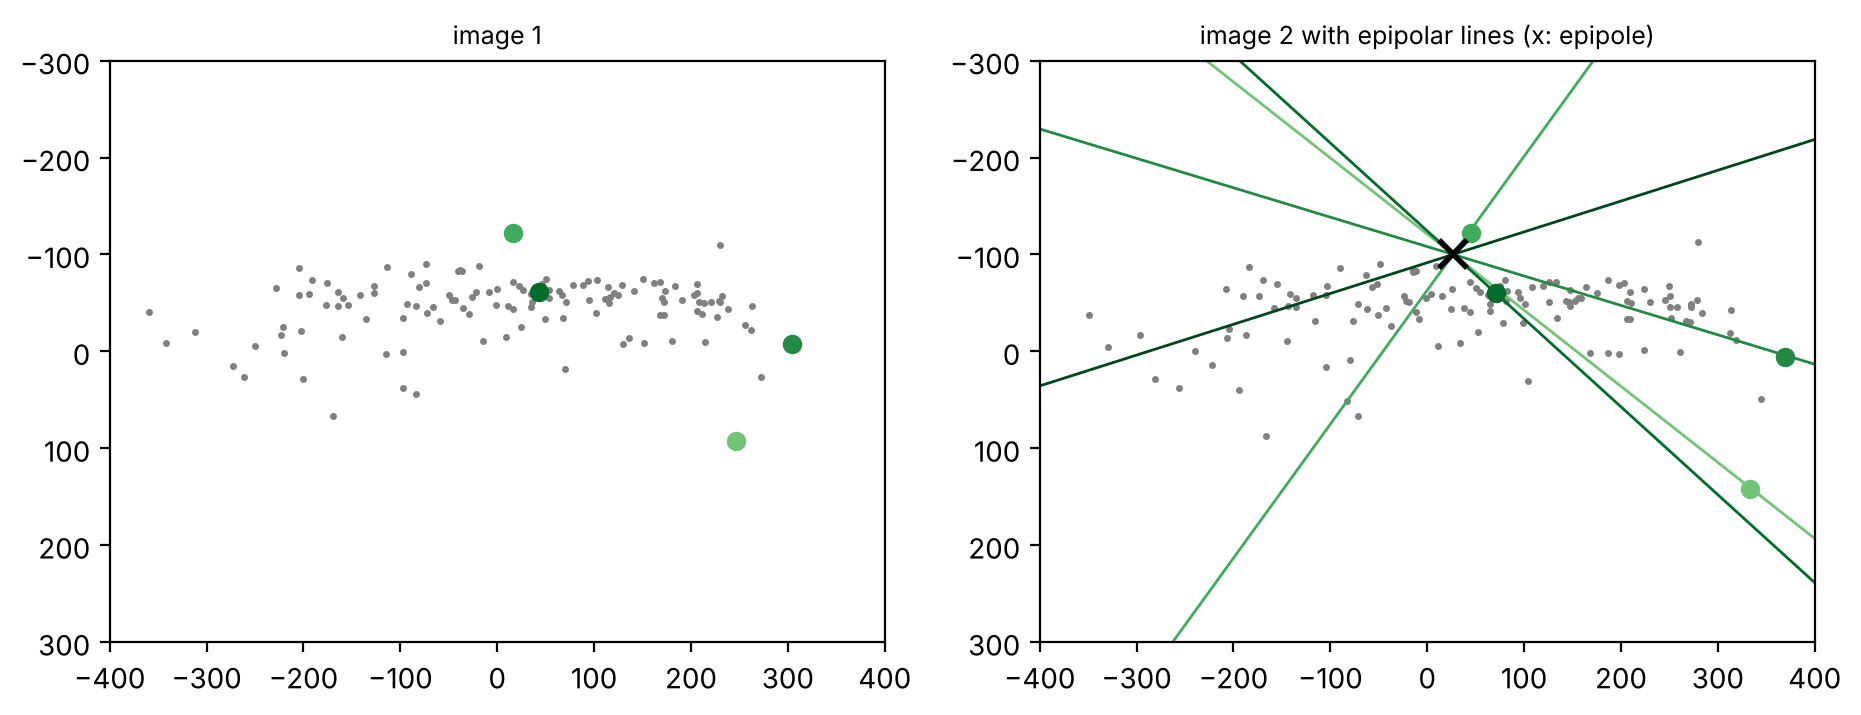

In [2]:
x1, x2, R, t, n = mower_scene(rng, relief=0.3, forward=0.3, yaw_deg=3.0)
E = tv.essential_from_pose(R, t)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(*(x1 * F_PX).T, ".", color="0.5", ms=3); ax[1].plot(*(x2 * F_PX).T, ".", color="0.5", ms=3)
us = np.linspace(-400, 400, 2)
for i, col in zip(range(0, 40, 8), plt.cm.Greens(np.linspace(0.5, 1, 5))):
    ax[0].plot(*(x1[i] * F_PX), "o", color=col)
    l = E @ np.append(x1[i], 1.0)                      # a u + b v + c = 0 in normalised coords
    ax[1].plot(us, -(l[0] * us / F_PX + l[2]) / l[1] * F_PX, color=col, lw=1)
    ax[1].plot(*(x2[i] * F_PX), "o", color=col)
e2 = t / t[2]                                          # epipole: image of camera 1's centre
ax[1].plot(e2[0] * F_PX, e2[1] * F_PX, "kx", ms=10, mew=2)
for a, title in zip(ax, ["image 1", "image 2 with epipolar lines (x: epipole)"]):
    a.set_xlim(-400, 400); a.set_ylim(300, -300); a.set_aspect("equal"); a.set_title(title, fontsize=9)

Moving forward puts the epipole inside the image, near its centre: points close to it barely move between the views,
which is the forward-motion problem of Section 6.4.

## 2. What makes a matrix essential (Theorem 6.3, Proposition 6.5)

In [3]:
print("singular values of E:", np.linalg.svd(E, compute_uv=False))
print("Demazure constraint |2EE^TE - tr(EE^T)E| =", np.abs(tv.demazure(E)).max())
M = rng.normal(size=(3, 3))
print("a random matrix violates it:            ", np.abs(tv.demazure(M)).max())

singular values of E: [0.3 0.3 0. ]
Demazure constraint |2EE^TE - tr(EE^T)E| = 6.938893903907228e-18
a random matrix violates it:             42.75470743635405


## 3. Four decompositions, one physical solution (Proposition 6.4)

In [4]:
for k, (Rc, tc) in enumerate(tv.decompose_essential(E)):
    X = tv.triangulate(Rc, tc, x1, x2)
    print(f"candidate {k}: rotation error {rot_err_deg(Rc, R):7.2f} deg, "
          f"t direction error {dir_err_deg(tc, t):6.1f} deg, in front of both: {tv.in_front(Rc, tc, X).mean():5.0%}")

candidate 0: rotation error    0.00 deg, t direction error    0.0 deg, in front of both:   99%
candidate 1: rotation error    0.00 deg, t direction error  180.0 deg, in front of both:    1%
candidate 2: rotation error  180.00 deg, t direction error    0.0 deg, in front of both:    0%
candidate 3: rotation error  180.00 deg, t direction error  180.0 deg, in front of both:    0%


## 4. A lawn and a garden

Relative-pose error of the three estimators on 20 random scenes each: a perfect lawn (no relief) and a garden with
0.3 m of relief. The homography decomposition is disambiguated with the known ground normal (Section 6.5).

In [5]:
for name, relief in [("lawn  ", 0.0), ("garden", 0.3)]:
    errs = {m: [] for m in ["eight-point", "five-point", "homography"]}
    for _ in range(20):
        a, b, R_, t_, n_ = mower_scene(rng, relief)
        for m, (Re, te) in estimate_all(a, b, n_, rng).items():
            errs[m].append((rot_err_deg(Re, R_), dir_err_deg(te, t_)))
    print(name, "  ".join(f"{m}: rot {np.median([e[0] for e in v]):5.2f}, t {np.median([e[1] for e in v]):5.1f} deg"
                          for m, v in errs.items()))

lawn   eight-point: rot 12.98, t 110.6 deg  five-point: rot  0.26, t   2.9 deg  homography: rot  0.06, t   0.6 deg


garden eight-point: rot  0.39, t   2.8 deg  five-point: rot  0.24, t   2.5 deg  homography: rot  0.13, t   2.0 deg


## 5. The planar ambiguity (Proposition 6.8)

On a plane the epipolar constraint no longer pins down $E$. The eight-point system loses rank (three singular values
at noise level instead of one). Worse, even the five-point solver can return a "twin" essential matrix that explains
every correspondence *and* puts every point in front of both cameras: nothing in the two images can tell it from the
truth.

In [6]:
a, b, R_, t_, n_ = mower_scene(np.random.default_rng(3), relief=0.0)
A = np.einsum("ni,nj->nij", tv.homog(b), tv.homog(a)).reshape(-1, 9)
print("smallest singular values of the 8-point system (noisy lawn):",
      np.linalg.svd(A, compute_uv=False)[5:].round(5))

found = 0
for seed in range(20):
    a, b, R_, t_, n_ = mower_scene(np.random.default_rng(seed), relief=0.0)
    E5, m5 = tv.five_point_ransac(a, b, 2.0 / F_PX)
    rp = tv.recover_pose(E5, a[m5], b[m5])
    if rot_err_deg(rp.R, R_) > 1.0:
        found += 1
        print(f"seed {seed:2d}: five-point rotation error {rot_err_deg(rp.R, R_):5.1f} deg, "
              f"points in front of both cameras {rp.in_front.mean():.0%}")
print(f"twin solution chosen in {found} of 20 lawns")

smallest singular values of the 8-point system (noisy lawn): [0.1427 0.0118 0.0113 0.004 ]
seed  1: five-point rotation error  20.7 deg, points in front of both cameras 100%
seed  2: five-point rotation error  20.4 deg, points in front of both cameras 100%
seed  4: five-point rotation error  23.6 deg, points in front of both cameras 100%
seed  7: five-point rotation error  21.1 deg, points in front of both cameras 100%
seed  9: five-point rotation error  20.5 deg, points in front of both cameras 100%
seed 11: five-point rotation error  22.9 deg, points in front of both cameras 100%


seed 16: five-point rotation error  21.6 deg, points in front of both cameras 100%
seed 19: five-point rotation error  19.7 deg, points in front of both cameras 100%
twin solution chosen in 8 of 20 lawns


## 6. Choosing the model automatically

Fit a homography to all the matches and ask whether it explains them at the noise level: with $\sigma$ in each image,
the transfer error of a point that obeys the homography is within $2.45\sqrt2\,\sigma$ with probability 95 %. If (almost)
all points pass, the scene is effectively planar and the homography model should be used; otherwise the essential
matrix. ORB-SLAM's initialisation implements a scored version of this test.

In [7]:
sigma = 0.5 / F_PX
for relief in [0.0, 0.01, 0.03, 0.1, 0.3, 1.0]:
    frac = []
    for s_ in range(10):
        a, b = mower_scene(np.random.default_rng(s_), relief)[:2]
        H, _ = cv2.findHomography(a, b, 0)            # least squares on all matches
        h = tv.homog(a) @ H.T
        d = np.linalg.norm(h[:, :2] / h[:, 2:] - b, axis=1)
        frac.append(np.mean(d < 2.45 * np.sqrt(2) * sigma))
    f = np.median(frac)
    print(f"relief {relief:4.2f} m: {f:4.0%} of points explained by H -> {'homography' if f > 0.85 else 'essential'}")

relief 0.00 m:  94% of points explained by H -> homography
relief 0.01 m:  93% of points explained by H -> homography
relief 0.03 m:  89% of points explained by H -> homography
relief 0.10 m:  70% of points explained by H -> essential
relief 0.30 m:  21% of points explained by H -> essential
relief 1.00 m:   5% of points explained by H -> essential


## 7. Triangulation and parallax (Proposition 6.7)

Depth from two views degrades like $1/\theta$, the angle between the rays. Moving forward, the parallax of a point
is roughly proportional to its angular distance from the epipole: straight ahead, nothing can be triangulated.

In [8]:
Rf, tf = np.eye(3), np.array([0.0, 0.0, -0.3])           # 30 cm straight ahead
for ang in [1, 5, 10, 20, 30]:
    X = np.array([[5 * np.tan(np.radians(ang)), 0.0, 5.0]])
    print(f"point {ang:2d} deg off the direction of motion: parallax {np.degrees(tv.parallax_angle(Rf, tf, X)[0]):.2f} deg")

point  1 deg off the direction of motion: parallax 0.06 deg
point  5 deg off the direction of motion: parallax 0.32 deg
point 10 deg off the direction of motion: parallax 0.62 deg
point 20 deg off the direction of motion: parallax 1.17 deg
point 30 deg off the direction of motion: parallax 1.56 deg


## 8. Try it yourself

* In section 4, set `yaw_deg=20` (the mower turning while it drives). Which estimator suffers most, and why?
* In section 6, the decision threshold is 85 %. Between which reliefs does the decision switch, and do the failure rates
  of Figure 6.3 agree with that choice?
* Triangulate points 1 m and 10 m ahead after a 30 cm forward move, with 0.5 px noise. Compare the depth errors with
  the stereo rig of Chapter 3.